# Breast Cancer Survival Prediction
## Notebook 1: Data Cleaning and Exploration

Author: Armaan Khan

This project uses a dataset of 4,024 breast cancer patients from the SEER cancer registry, which is run by the US National Cancer Institute. It looks at two research questions:

1. Does machine learning have the potential to help doctors predict which patients will survive breast cancer and which will not? (classification, Notebooks 2 and 3)
2. For the patients who will not survive, can it predict how many months they will survive for? (regression, Notebook 3)

In this notebook I explore the dataset, decide which variables to keep, find the issues in the data and fix them, so the data is ready for modelling.

In [1]:
# Importing the libraries needed for this notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Controlling the default Pandas truncation of the rows and columns
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 150)

# Setting the colours and style used in the charts
ALIVE, DEAD, MAIN = "#8c9bab", "#e4572e", "#1f77b4"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Exploring the dataset

In [2]:
# Loading the dataset file (see data/README.md for where it comes from)
raw = pd.read_csv("data/breast_cancer.csv")

# Displaying the first 10 rows of the dataset before cleaning to inspect it
raw.head(10)

,Patient_ID,Month_of_Birth,Age,Sex,Occupation,T_Stage,N_Stage,6th_Stage,Differentiated,Grade,A_Stage,Tumor_Size,Estrogen_Status,Progesterone_Status,Regional_Node_Examined,Reginol_Node_Positive,Survival_Months,Mortality_Status
0,A0012,12,68.0,Female,Teaching,T1,N1,IIA,Poorly differentiated,3,Regional,4.0,Positive,Positive,24.0,1.0,60,Alive
1,A0013,12,50.0,Female,Medical,T2,N2,IIIA,Moderately differentiated,2,Regional,35.0,Positive,Positive,14.0,5.0,62,Alive
2,A0014,11,58.0,Female,Engineering,T3,N3,IIIC,Moderately differentiated,2,Regional,63.0,Positive,Positive,14.0,7.0,75,Alive
3,A0015,3,58.0,Female,Technology,T1,N1,IIA,Poorly differentiated,3,Regional,18.0,Positive,Positive,2.0,1.0,84,Alive
4,A0016,1,47.0,Female,Multimedia,T2,N1,IIB,Poorly differentiated,3,Regional,41.0,Positive,Positive,3.0,1.0,50,Alive
5,A0017,2,51.0,Female,Research,T1,N1,IIA,Moderately differentiated,2,Regional,20.0,Positive,Positive,18.0,2.0,89,Alive
6,A0018,5,51.0,Female,House Person,T1,N1,IIA,Well differentiated,1,Regional,8.0,Positive,Positive,11.0,1.0,54,Alive
7,A0019,4,40.0,Female,Reporting,T2,N1,IIB,Moderately differentiated,2,Regional,30.0,Positive,Positive,9.0,1.0,14,Dead
8,A0020,6,40.0,Female,Development,T4,N3,IIIC,Poorly differentiated,3,Regional,103.0,Positive,Positive,20.0,18.0,70,Alive
9,A0021,4,69.0,Female,Construction,T4,N3,IIIC,Well differentiated,1,Distant,32.0,Positive,Positive,21.0,12.0,92,Alive


In [3]:
# Checking the dimensions (number of rows and columns) of the dataset
raw.shape

(4024, 18)

In [4]:
# Exploring the data types and the number of non-missing values for every variable
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Patient_ID              4024 non-null   str    
 1   Month_of_Birth          4024 non-null   int64  
 2   Age                     4015 non-null   float64
 3   Sex                     4024 non-null   str    
 4   Occupation              86 non-null     str    
 5   T_Stage                 4024 non-null   str    
 6   N_Stage                 4024 non-null   str    
 7   6th_Stage               4024 non-null   str    
 8   Differentiated          4024 non-null   str    
 9   Grade                   4024 non-null   int64  
 10  A_Stage                 4016 non-null   str    
 11  Tumor_Size              4021 non-null   float64
 12  Estrogen_Status         4024 non-null   str    
 13  Progesterone_Status     4024 non-null   str    
 14  Regional_Node_Examined  4008 non-null   float64
 15

In [5]:
# Displaying basic descriptive stats for the numeric variables
raw.describe().round(1)

,Month_of_Birth,Age,Grade,Tumor_Size,Regional_Node_Examined,Reginol_Node_Positive,Survival_Months
count,4024.0,4015.0,4024.0,4021.0,4008.0,3970.0,4024.0
mean,6.5,54.0,2.2,30.5,14.4,5042.9,71.5
std,3.5,9.0,0.6,21.1,8.2,317482.7,25.4
min,1.0,30.0,1.0,1.0,-18.0,1.0,1.0
25%,3.0,47.0,2.0,16.0,9.0,1.0,56.0
50%,6.0,54.0,2.0,25.0,14.0,2.0,73.0
75%,10.0,61.0,3.0,38.0,19.0,5.0,90.0
max,12.0,89.0,4.0,140.0,61.0,20003933.0,760.0


In [6]:
# Displaying basic descriptive stats for the categorical variables
raw.describe(exclude="number")

,Patient_ID,Sex,Occupation,T_Stage,N_Stage,6th_Stage,Differentiated,A_Stage,Estrogen_Status,Progesterone_Status,Mortality_Status
count,4024,4024,86,4024,4024,4024,4024,4016,4024,4024,4024
unique,4024,2,40,4,3,5,4,2,2,2,7
top,A0012,Female,House Person,T2,N1,IIA,Moderately differentiated,Regional,Positive,Positive,Alive
freq,1,2561,4,1786,2732,1305,2351,3924,3755,3326,3399


In [7]:
# Checking the unique values in all the categorical variables
categorical = ["Sex", "T_Stage", "N_Stage", "6th_Stage", "Differentiated", "A_Stage",
               "Estrogen_Status", "Progesterone_Status", "Mortality_Status"]
for col in categorical:
    print(col, list(raw[col].unique()))

Sex ['Female', 'Male']
T_Stage ['T1', 'T2', 'T3', 'T4']
N_Stage ['N1', 'N2', 'N3']
6th_Stage ['IIA', 'IIIA', 'IIIC', 'IIB', 'IIIB']
Differentiated ['Poorly differentiated', 'Moderately differentiated', 'Well differentiated', 'Undifferentiated']
A_Stage ['Regional', 'Distant', nan]
Estrogen_Status ['Positive', 'Negative']
Progesterone_Status ['Positive', 'Negative']
Mortality_Status ['Alive', 'Dead', 'ALIVE', 'DEAD', 'ALive', 'alive', 'dead']


In [8]:
# Checking the number and percentage of missing values in each variable
missing = pd.DataFrame({"Missing": raw.isnull().sum(), "Percent": (raw.isnull().mean() * 100).round(2)})
missing[missing["Missing"] > 0]

,Missing,Percent
Age,9,0.22
Occupation,3938,97.86
A_Stage,8,0.20
Tumor_Size,3,0.07
Regional_Node_Examined,16,0.40
Reginol_Node_Positive,54,1.34


In [9]:
# Checking if any patient appears twice (the ID is left out because it is always different)
raw.drop(columns="Patient_ID").duplicated().sum()

np.int64(0)

### Distributions of the numeric variables

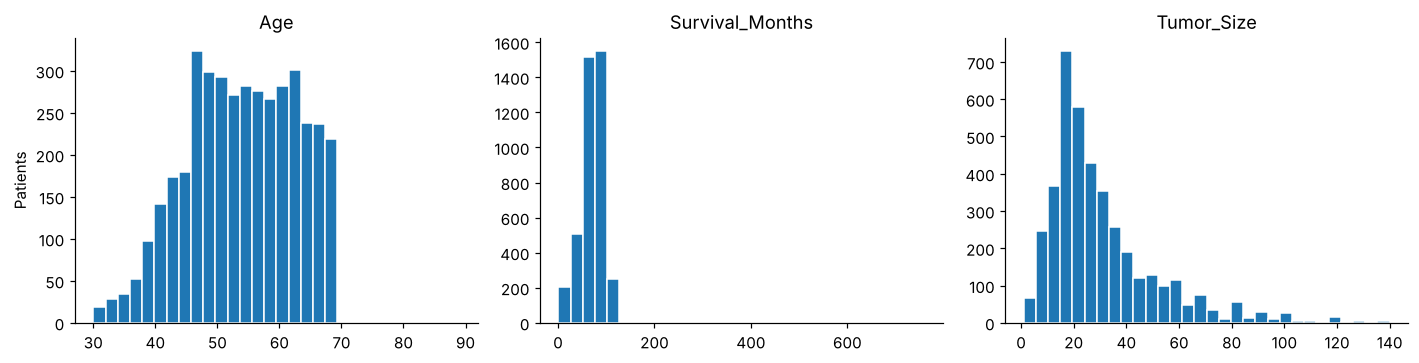

In [10]:
# Plotting histograms for the numeric variables to explore their frequency distributions
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col in zip(axes, ["Age", "Survival_Months", "Tumor_Size"]):
    ax.hist(raw[col].dropna(), bins=30, color=MAIN, edgecolor="white")
    ax.set_title(col)
axes[0].set_ylabel("Patients")
plt.tight_layout()
plt.show()

The Survival_Months histogram is stretched all the way out to 760, even though almost every patient is under 110 months. This shows there is an extreme outlier. Age and Tumor_Size also have a few values far from the rest.

### Box plots to detect outliers

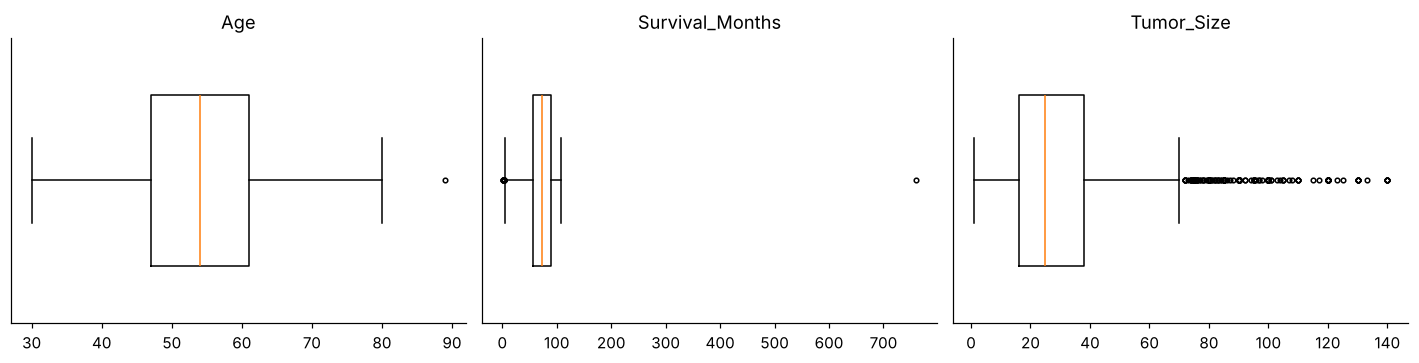

In [11]:
# Plotting box plots for the numeric variables to detect outliers
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col in zip(axes, ["Age", "Survival_Months", "Tumor_Size"]):
    ax.boxplot(raw[col].dropna(), orientation="horizontal", widths=0.6, flierprops={"markersize": 3})
    ax.set_title(col)
    ax.set_yticks([])
plt.tight_layout()
plt.show()

In [12]:
# Creating a function to detect outliers based on the Interquartile Range (IQR)
def find_outliers_IQR(data):
    q1 = data.quantile(0.25)  # Calculating the first quartile (Q1)
    q3 = data.quantile(0.75)  # Calculating the third quartile (Q3)
    IQR = q3 - q1  # Calculating the interquartile range (IQR)

    # Identifying values that fall below Q1 - 1.5*IQR or above Q3 + 1.5*IQR
    return data[(data < (q1 - 1.5 * IQR)) | (data > (q3 + 1.5 * IQR))]


# Calling the function on each numeric variable
for col in ["Age", "Survival_Months", "Tumor_Size", "Regional_Node_Examined", "Reginol_Node_Positive"]:
    outliers = find_outliers_IQR(raw[col].dropna())
    print(f"{col}: {len(outliers)} outliers, values from {outliers.min()} to {outliers.max()}")

Age: 1 outliers, values from 89.0 to 89.0
Survival_Months: 19 outliers, values from 1 to 760
Tumor_Size: 221 outliers, values from 72.0 to 140.0
Regional_Node_Examined: 74 outliers, values from -18.0 to 61.0
Reginol_Node_Positive: 339 outliers, values from 12.0 to 20003933.0


The IQR function flags a lot of values, but not all of them are errors. For example, the 18 low Survival_Months values (1 to 4 months) are patients who sadly died soon after diagnosis, and large tumours and high node counts are real in breast cancer. So I only treat a value as an error if it is impossible or clearly doesn't fit with the rest of the data:

- Survival_Months of 760 (over 63 years), when every other value is between 1 and 107
- Ages of 80 and 89, when every other patient is between 30 and 69
- Negative values for Regional_Node_Examined, which is a count
- A Reginol_Node_Positive value of 20,003,933, which is more positive nodes than were examined

In [13]:
# Checking the impossible values listed above
print("Survival months over 107:", raw.loc[raw["Survival_Months"] > 107, "Survival_Months"].tolist())
print("Ages over 69:", raw.loc[raw["Age"] > 69, "Age"].tolist())
print("Negative nodes examined:", raw.loc[raw["Regional_Node_Examined"] < 0, "Regional_Node_Examined"].tolist())
print("More positive nodes than examined:")
raw.loc[raw["Reginol_Node_Positive"] > raw["Regional_Node_Examined"], ["Regional_Node_Examined", "Reginol_Node_Positive"]]

Survival months over 107: [760]
Ages over 69: [80.0, 89.0]
Negative nodes examined: [-18.0, -2.0, -5.0]
More positive nodes than examined:


,Regional_Node_Examined,Reginol_Node_Positive
18,-18.0,1.0
204,-2.0,1.0
380,-5.0,2.0
544,33.0,20003933.0


## 2. Variables to retain or drop

| Variable | Retain or drop | Justification |
|---|---|---|
| Patient_ID | Drop | A patient's ID does not provide any useful information that can be used to predict breast cancer. Removing it will reduce noise. |
| Month_of_Birth | Drop | Similarly to Patient ID, a patient's month of birth does not provide any useful information, especially since we already have the ages of the patients. |
| Age | Retain | Age is very important for predicting breast cancer mortality. Younger patients under 40 and older patients over 80 have poorer chances of survival (Brandt et al., 2015). |
| Sex | Drop | 1,463 patients (36%) are recorded as male, but men only make up around 1% of breast cancer cases in the general population. This shows the variable can't be trusted, and dropping it also helps the model focus on the other variables. |
| Occupation | Drop | Only 86 patients out of over 4,000 had a recorded occupation (98% of the values are missing), so it makes sense to drop it. |
| T_Stage | Retain | T stage represents the size category of the tumour, which is important for predicting breast cancer as the larger the tumour, the worse the outcome. |
| N_Stage | Retain | N stage indicates whether the cancer has spread to nearby lymph nodes. This spread is a good predictor of how severe the cancer is, so it will be kept. |
| 6th_Stage | Drop | This is the overall stage of the cancer (from the 6th edition of the AJCC staging system), which is worked out from the T and N stages. Both of these are already retained, so keeping it would count the same information twice. |
| Differentiated | Drop | This describes how abnormal the cancer cells look, which is exactly what Grade measures. Every Differentiated label matches one Grade (shown in section 3), so keeping both would count the same thing twice. |
| Grade | Retain | Grade represents how aggressive the tumour is. The higher the grade, the lower the survival rate, and research confirms that grade is an independent predictor of breast cancer death across all subtypes (Johansson et al., 2021). |
| A_Stage | Retain | A stage shows whether the cancer has spread regionally or to distant parts of the body, which is important for predicting survival. |
| Tumor_Size | Retain | A larger tumour size generally means that the disease is more developed, so this should be kept to show the severity of the breast cancer. |
| Estrogen_Status | Retain | This affects the type of treatment a patient might receive. Oestrogen positive patients can benefit from hormone therapies, which can improve their survival rate. |
| Progesterone_Status | Retain | Similarly to oestrogen status, this affects the type of treatment a patient might receive, which can improve their survival rate. |
| Regional_Node_Examined | Retain | The number of lymph nodes examined shows how thoroughly the cancer was checked, which can affect how reliable the staging is. |
| Reginol_Node_Positive | Retain | The more positive nodes a patient has, the lower their survival rate, so it should be kept. |
| Survival_Months | Retain (regression target) | This is the target variable for the regression in Notebook 3. It isn't used as an input for the classification, as it is only known after the outcome. |
| Mortality_Status | Retain (classification target) | This is the target variable for the classification, as it categorises the patients into alive or dead. |

## 3. Issues found in the retained variables and how I fix them

| # | Variable | Issue found | Fix | Justification |
|---|---|---|---|---|
| 1 | Reginol_Node_Positive | Spelling mistake in the name | Rename | The variable was spelt "Reginol", so it was renamed to Regional_Node_Positive to keep the dataset consistent. |
| 2 | Mortality_Status | Inconsistent case (Alive, ALIVE, ALive, alive, Dead, DEAD, dead) | Make lower case, then map to binary | Without this, Alive and ALIVE would be counted as different values. Once they are all lower case I map them to a binary variable called Died. |
| 3 | Survival_Months | Extreme outlier of 760 | Remove the patient | 760 months is over 63 years, which is very unrealistic, and every other value is between 1 and 107. Keeping it would negatively affect the models. |
| 4 | Age | Two outliers (80 and 89) | Replace with missing | Every other patient is between 30 and 69, so these are most likely errors. I replace them with missing values instead of deleting the patients, so the rest of their record is kept. |
| 5 | Regional_Node_Examined | Three negative values (-18, -5 and -2) | Replace with missing | This is a count of nodes, so it can't be negative. |
| 6 | Regional_Node_Positive | One value of 20,003,933 | Replace with missing | Only 33 nodes were examined for this patient, so having over 20 million positive nodes is impossible. |
| 7 | A_Stage | 8 missing values | Case-wise deletion | A_Stage is categorical (Regional or Distant), so filling it with a mean doesn't make sense. Only 8 patients are affected, so I remove them. |
| 8 | T_Stage, N_Stage, A_Stage, Estrogen_Status, Progesterone_Status | Text values | Map to numbers | The models can't process text. The stages are mapped in order of severity, because a label encoder would order them alphabetically instead of by severity. |
| 9 | Age, Tumor_Size, Regional_Node_Examined, Regional_Node_Positive | Missing values (under 2% in each) | Mean imputation, inside the model pipelines | The mean is worked out from the training data only, after the data has been split (see section 5). |

## 4. Fixing the issues

In [14]:
# Making a copy of the dataset so the raw data stays untouched
df = raw.copy()

# Showing that every Differentiated label matches exactly one Grade
pd.crosstab(df["Differentiated"], df["Grade"])

Grade,1,2,3,4
Differentiated,,,,
Moderately differentiated,0,2351,0,0
Poorly differentiated,0,0,1111,0
Undifferentiated,0,0,0,19
Well differentiated,543,0,0,0


In [15]:
# Dropping the variables I decided not to retain
df = df.drop(columns=["Patient_ID", "Month_of_Birth", "Sex", "Occupation", "6th_Stage", "Differentiated"])

# Fix 1: renaming the incorrectly spelled column
df = df.rename(columns={"Reginol_Node_Positive": "Regional_Node_Positive"})

# Checking the variables were successfully dropped and renamed
list(df.columns)

['Age',
 'T_Stage',
 'N_Stage',
 'Grade',
 'A_Stage',
 'Tumor_Size',
 'Estrogen_Status',
 'Progesterone_Status',
 'Regional_Node_Examined',
 'Regional_Node_Positive',
 'Survival_Months',
 'Mortality_Status']

**Fix 2:** after making the labels lower case, I map them to a new variable called Died, where 1 means the patient died and 0 means they are alive. I use 1 for dead because that is the outcome the models need to find. Scikit-learn's precision, recall and F1-score are worked out for class 1 by default, so this way they show how well each model finds the patients who died.

In [16]:
# Before: the same two values written seven different ways
print(df["Mortality_Status"].value_counts(), "\n")

# Converting all the text to lower case, then mapping to binary (dead = 1, alive = 0)
df["Mortality_Status"] = df["Mortality_Status"].str.strip().str.lower()
df["Died"] = df["Mortality_Status"].map({"dead": 1, "alive": 0})
df = df.drop(columns="Mortality_Status")

# After
print(df["Died"].value_counts())

Mortality_Status
Alive    3399
Dead      598
DEAD       10
dead        8
ALIVE       5
alive       3
ALive       1
Name: count, dtype: int64 

Died
0    3408
1     616
Name: count, dtype: int64


In [17]:
# Fix 3: removing the patient with the impossible survival time
print("Highest survival months before:", df["Survival_Months"].max())
df = df[df["Survival_Months"] != 760]
print("Highest survival months after:", df["Survival_Months"].max())

# Fix 4: replacing the two outlier ages with missing values
df.loc[df["Age"] > 69, "Age"] = np.nan
print("Age range after:", df["Age"].min(), "to", df["Age"].max())

# Fix 5: replacing the negative counts of nodes examined with missing values
df.loc[df["Regional_Node_Examined"] < 0, "Regional_Node_Examined"] = np.nan
print("Nodes examined range after:", df["Regional_Node_Examined"].min(), "to", df["Regional_Node_Examined"].max())

# Fix 6: replacing the impossible number of positive nodes with a missing value
df.loc[df["Regional_Node_Positive"] > df["Regional_Node_Examined"], "Regional_Node_Positive"] = np.nan
print("Nodes positive range after:", df["Regional_Node_Positive"].min(), "to", df["Regional_Node_Positive"].max())

Highest survival months before: 760
Highest survival months after: 107
Age range after: 30.0 to 69.0
Nodes examined range after: 1.0 to 61.0
Nodes positive range after: 1.0 to 46.0


In [18]:
# Fix 7: case-wise deletion of the patients with a missing A_Stage
print("Patients before:", len(df))
df = df.dropna(subset=["A_Stage"])
print("Patients after:", len(df))

Patients before: 4023
Patients after: 4015


In [19]:
# Fix 8: mapping the text values to numbers, keeping the order of severity for the stages
mappings = {
    "T_Stage": {"T1": 1, "T2": 2, "T3": 3, "T4": 4},
    "N_Stage": {"N1": 1, "N2": 2, "N3": 3},
    "A_Stage": {"Regional": 0, "Distant": 1},
    "Estrogen_Status": {"Negative": 0, "Positive": 1},
    "Progesterone_Status": {"Negative": 0, "Positive": 1},
}

for col, mapping in mappings.items():
    df[col] = df[col].map(mapping)
    print(col, mapping)

# Checking the variables' data types to make sure there are no text (object) columns left
df.dtypes

T_Stage {'T1': 1, 'T2': 2, 'T3': 3, 'T4': 4}
N_Stage {'N1': 1, 'N2': 2, 'N3': 3}
A_Stage {'Regional': 0, 'Distant': 1}
Estrogen_Status {'Negative': 0, 'Positive': 1}
Progesterone_Status {'Negative': 0, 'Positive': 1}


Age                       float64
T_Stage                     int64
N_Stage                     int64
Grade                       int64
A_Stage                     int64
Tumor_Size                float64
Estrogen_Status             int64
Progesterone_Status         int64
Regional_Node_Examined    float64
Regional_Node_Positive    float64
Survival_Months             int64
Died                        int64
dtype: object

## 5. Missing values

The remaining missing values are shown below. These are the original missing values plus the outliers I replaced.

I don't fill them in here. If I worked out the mean using the whole dataset now, the patients who end up in the test set would affect the data the models are trained on, which is called data leakage. So instead, the mean imputation happens inside each model's pipeline in Notebooks 2 and 3, after the data has been split, using the training data only.

In [20]:
# Checking the remaining missing values
remaining = df.isnull().sum()
remaining[remaining > 0]

Age                       11
Tumor_Size                 3
Regional_Node_Examined    18
Regional_Node_Positive    55
dtype: int64

## 6. Exploring the cleaned dataset

### Basic descriptive stats

In [21]:
# Basic descriptive stats for the retained input variables and the target, after cleaning
df.describe().round(2)

,Age,T_Stage,N_Stage,Grade,A_Stage,Tumor_Size,Estrogen_Status,Progesterone_Status,Regional_Node_Examined,Regional_Node_Positive,Survival_Months,Died
count,4004.00,4015.00,4015.00,4015.00,4015.00,4012.00,4015.00,4015.00,3997.00,3960.00,4015.00,4015.00
mean,53.98,1.78,1.44,2.15,0.02,30.43,0.93,0.83,14.37,4.14,71.31,0.15
std,8.96,0.77,0.69,0.64,0.15,21.06,0.25,0.38,8.13,5.09,22.91,0.36
min,30.00,1.00,1.00,1.00,0.00,1.00,0.00,0.00,1.00,1.00,1.00,0.00
25%,47.00,1.00,1.00,2.00,0.00,16.00,1.00,1.00,9.00,1.00,56.00,0.00
50%,54.00,2.00,1.00,2.00,0.00,25.00,1.00,1.00,14.00,2.00,73.00,0.00
75%,61.00,2.00,2.00,3.00,0.00,38.00,1.00,1.00,19.00,5.00,90.00,0.00
max,69.00,4.00,3.00,4.00,1.00,140.00,1.00,1.00,61.00,46.00,107.00,1.00


### Variable scale types

| Variable | Scale type |
|---|---|
| Age | Ratio |
| T_Stage | Ordinal |
| N_Stage | Ordinal |
| Grade | Ordinal |
| A_Stage | Nominal (binary) |
| Tumor_Size | Ratio |
| Estrogen_Status | Nominal (binary) |
| Progesterone_Status | Nominal (binary) |
| Regional_Node_Examined | Ratio |
| Regional_Node_Positive | Ratio |
| Survival_Months | Ratio |
| Died (target) | Nominal (binary) |

### Distribution of the target variable

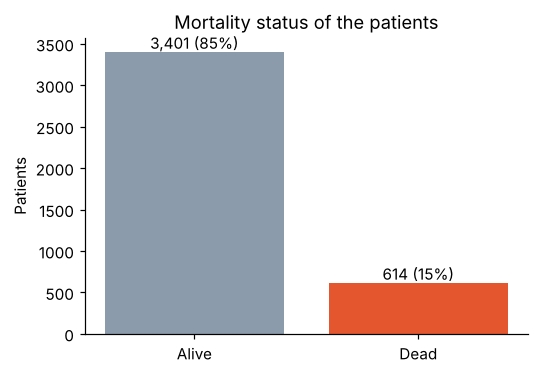

In [22]:
counts = df["Died"].value_counts().sort_index()

# Plotting a bar chart of the target variable, with the count and percentage on each bar
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(["Alive", "Dead"], counts.values, color=[ALIVE, DEAD])
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 40, f"{n:,} ({n / len(df):.0%})", ha="center")
ax.set_ylabel("Patients")
ax.set_title("Mortality status of the patients")
plt.tight_layout()
plt.savefig("images/class_balance.png", bbox_inches="tight")
plt.show()

Only 15% of the patients died, so the dataset is imbalanced. This is important for the modelling, because a model could simply predict the majority class (alive) for every patient and still be around 85% accurate, without finding a single patient who died.

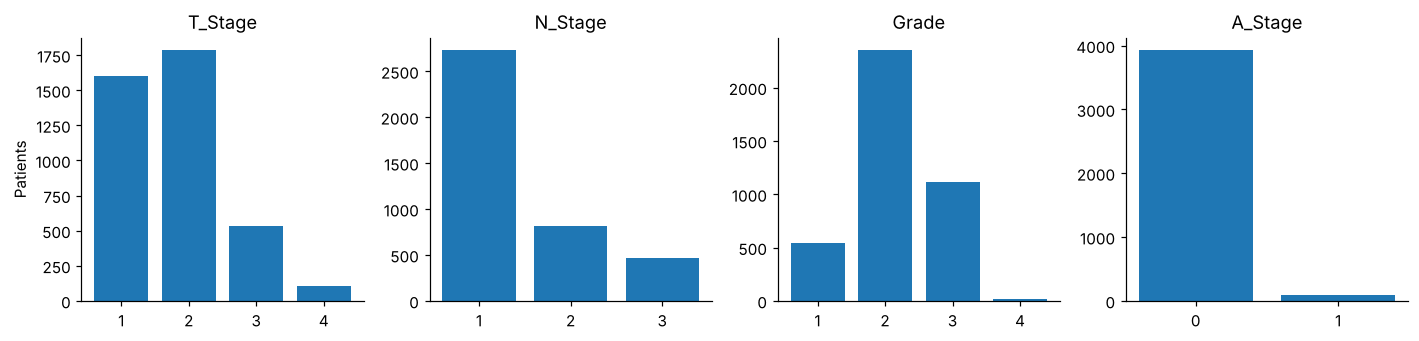

In [23]:
# Plotting bar charts for the stage and grade variables to explore their frequency distributions
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, col in zip(axes, ["T_Stage", "N_Stage", "Grade", "A_Stage"]):
    counts = df[col].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color=MAIN)
    ax.set_title(col)
axes[0].set_ylabel("Patients")
plt.tight_layout()
plt.show()

Most patients have an early T stage (T1 or T2), N1 and a grade of 2, and only 2% have distant spread (A_Stage = 1). Grade 4 only has 18 patients.

## 7. Exporting the cleaned dataset

In [24]:
# Exporting the cleaned dataset for the machine learning modelling in Notebooks 2 and 3
df.to_csv("data/cleaned_breast_cancer.csv", index=False)
df.shape

(4015, 12)

## References

Brandt, J., Garne, J.P., Tengrup, I. and Manjer, J. (2015). Age at diagnosis in relation to survival following breast cancer: a cohort study. *World Journal of Surgical Oncology*, 13(1), p.33. https://doi.org/10.1186/s12957-014-0429-x

Johansson, A.L.V., Trewin, C.B., Fredriksson, I., Reinertsen, K.V., Russnes, H. and Ursin, G. (2021). In modern times, how important are breast cancer stage, grade and receptor subtype for survival: a population-based cohort study. *Breast Cancer Research*, 23(1), p.17. https://doi.org/10.1186/s13058-021-01393-z